In [34]:
#libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#import data
train_data = pd.read_csv('train.csv')

#first 5 rows
print("First Five Rows:")
print(train_data.head())
print()

#dataset dimensions, column names, and data types
print("Dataset Dimensions:")
print(f"Rows: {train_data.shape[0]}, Columns: {train_data.shape[1]}")
print("Column Names and Data Types")
print(train_data.dtypes)
print()

#identify numerical and categorical variables
numerical_cols = train_data.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = train_data.select_dtypes(include=['string', 'category', 'bool']).columns.tolist()
print("Variable Types:")
print(f"Numerical Variables: {numerical_cols}")
print(f"Categorical Variables: {categorical_cols}")
print()

#calculate the number and percentage of missing values
missing_count = train_data.isna().sum()
missing_pct = (missing_count / len(train_data)) * 100
missing_df = pd.DataFrame({
    'Missing Count': missing_count,
    'Missing Percentage (%)': missing_pct.round(2)
})
print("Missing Values:")
print(missing_df[missing_df['Missing Count'] > 0])
print()

#check for duplicates
duplicates = train_data.duplicated().sum()
print("Duplicate Records:")
print(f"Number of exact duplicate rows: {duplicates}")
print()

#identify potential outliers in Age and Fare using the IQR method
def detect_outliers_iqr(data, column):
    series = data[column].dropna()
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[(data[column] < lower_bound) | (data[column] > upper_bound)]
    return len(outliers), lower_bound, upper_bound

age_outliers, age_low, age_high = detect_outliers_iqr(train_data, 'Age')
fare_outliers, fare_low, fare_high = detect_outliers_iqr(train_data, 'Fare')

print("Outliers (IQR Method):")
print(f"Age: {age_outliers} outliers (Bounds: {age_low:.2f} to {age_high:.2f})")
print(f"Fare: {fare_outliers} outliers (Bounds: {fare_low:.2f} to {fare_high:.2f})")
print()

#Findings
print("Findings:")
print("I think the first part of this assignment will help with the rest of it as this part has given me\nimportant insights into what is going on with the data. Knowing all of the column names and \nwhat data is missing will be especially valuable.")

First Five Rows:
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   

In [24]:
#create a copy of the original dataframe
#this is done to preserve the original data
cleaned_data = train_data.copy()

#handle missing values in age, cabin, and embarked
#I am choosing to impute age using median age group to retain sample size and reduce bias as opposed to if I removed it
cleaned_data['Age'] = cleaned_data['Age'].fillna(
    cleaned_data.groupby(['Pclass', 'Sex'])['Age'].transform('median')
)

#I will impute embarked using mode because there's only .22% missing and it won't create too much of a bias
embarked_mode = cleaned_data['Embarked'].mode()[0]
cleaned_data['Embarked'] = cleaned_data['Embarked'].fillna(embarked_mode)

#Cabin has 77.1% missing and so imputing it would create too big of a bias. I think it is best to drop the column after extracting if they had a cabin
#This way some data is retained to show who did and didn't have cabin data recorded
cleaned_data['Has_Cabin'] = cleaned_data['Cabin'].notna().astype('int64')
cleaned_data = cleaned_data.drop(columns=['Cabin'])
#double checking
print(cleaned_data['Has_Cabin'].value_counts())

#investigate potential outliers
#I will look at this for Age and Fare since that is what we did in the first part of the assignment
print("Extreme Fare Records (> $300):")
print(cleaned_data[cleaned_data['Fare'] > 300][['PassengerId', 'Pclass', 'Name', 'Fare', 'Survived']])
print()
print("Elderly Age Records (>65):")
print(cleaned_data[cleaned_data['Age'] > 65][['PassengerId', 'Pclass', 'Name', 'Age', 'Survived']])
#I don't see anything wrong with these outliers so I will leave the data in.
#All of the data seems valid and worthy of leaving

#check and correct inappropriate data types
#convert survived, pclass, sex, and embarked into category data type
#this will help distiguish them from numerical columns
categorical_cols = ['Survived', 'Pclass', 'Sex', 'Embarked']
for col in categorical_cols:
    cleaned_data[col] = cleaned_data[col].astype('category')

#validate the cleaned dataset
print("\nValidation: Remaining Missing Values")
print(cleaned_data.isna().sum())
print("\nValidation: Duplicate Records")
print(f"Exact duplicate rows: {cleaned_data.duplicated().sum()}")
print("\nValidation: Updated Data Types")
print(cleaned_data.dtypes)
print("\nValidation: Cleaned Dataset Shape")
print(f"Rows: {cleaned_data.shape[0]}, Columns: {cleaned_data.shape[1]}")

print("\nDocumentation:")
print("I documented my thought process and explanations within the code as comments.")

Has_Cabin
0    687
1    204
Name: count, dtype: int64
Extreme Fare Records (> $300):
     PassengerId  Pclass                                Name      Fare  \
258          259       1                    Ward, Miss. Anna  512.3292   
679          680       1  Cardeza, Mr. Thomas Drake Martinez  512.3292   
737          738       1              Lesurer, Mr. Gustave J  512.3292   

     Survived  
258         1  
679         1  
737         1  

Elderly Age Records (>65):
     PassengerId  Pclass                                  Name   Age  Survived
33            34       2                 Wheadon, Mr. Edward H  66.0         0
96            97       1             Goldschmidt, Mr. George B  71.0         0
116          117       3                  Connors, Mr. Patrick  70.5         0
493          494       1               Artagaveytia, Mr. Ramon  71.0         0
630          631       1  Barkworth, Mr. Algernon Henry Wilson  80.0         1
672          673       2           Mitchell, Mr. Hen

In [30]:
#statistics for age and fare
num_cols = ['Age', 'Fare']
stats = pd.DataFrame({
    'Mean': cleaned_data[num_cols].mean(),
    'Median': cleaned_data[num_cols].median(),
    'Min': cleaned_data[num_cols].min(),
    'Max': cleaned_data[num_cols].max(),
    'Range': cleaned_data[num_cols].max() - cleaned_data[num_cols].min(),
    'Variance': cleaned_data[num_cols].var(),
    'Std Dev': cleaned_data[num_cols].std(),
    'Q1 (25%)': cleaned_data[num_cols].quantile(0.25),
    'Q3 (75%)': cleaned_data[num_cols].quantile(0.75),
})
stats['IQR'] = stats['Q3 (75%)'] - stats['Q1 (25%)']

print("Numerical Summary Statistics for Age and Fare")
print(stats.round(2))

#frequency and % for sex, pclass, and survived
cat_cols = ['Sex', 'Pclass', 'Survived']
print("\nCategorical Frequencies and Percentages")
for col in cat_cols:
    freq = cleaned_data[col].value_counts()
    pct = cleaned_data[col].value_counts(normalize=True) * 100
    summary = pd.DataFrame({'Frequency': freq, 'Percentage (%)': pct.round(2)})
    print(f"\n[{col}]")
    print(summary)

#compare average fare across passenger classes
print("\nAverage and Median Fare by Class")
fare_by_class = cleaned_data.groupby('Pclass', observed=False)['Fare'].agg(
    Mean_Fare='mean',
    Median_Fare='median',
    Std_Dev='std'
).round(2)
print(fare_by_class)

#Findings
print("\nFindings:")
print("The 3rd class passengers accounted for over half of the passengers. In addition\nover half of the passengers were male. Only 38.38% of passengers survived. In terms\nof fare the data is heavily skewed due to the max being so high so the most accurate\nmay be the median value of $14.45.")

Numerical Summary Statistics for Age and Fare
       Mean  Median   Min     Max   Range  Variance  Std Dev  Q1 (25%)  \
Age   29.11   26.00  0.42   80.00   79.58    177.01    13.30     21.50   
Fare  32.20   14.45  0.00  512.33  512.33   2469.44    49.69      7.91   

      Q3 (75%)    IQR  
Age       36.0  14.50  
Fare      31.0  23.09  

Categorical Frequencies and Percentages

[Sex]
        Frequency  Percentage (%)
Sex                              
male          577           64.76
female        314           35.24

[Pclass]
        Frequency  Percentage (%)
Pclass                           
3             491           55.11
1             216           24.24
2             184           20.65

[Survived]
          Frequency  Percentage (%)
Survived                           
0               549           61.62
1               342           38.38

Average and Median Fare by Class
        Mean_Fare  Median_Fare  Std_Dev
Pclass                                 
1           84.15        

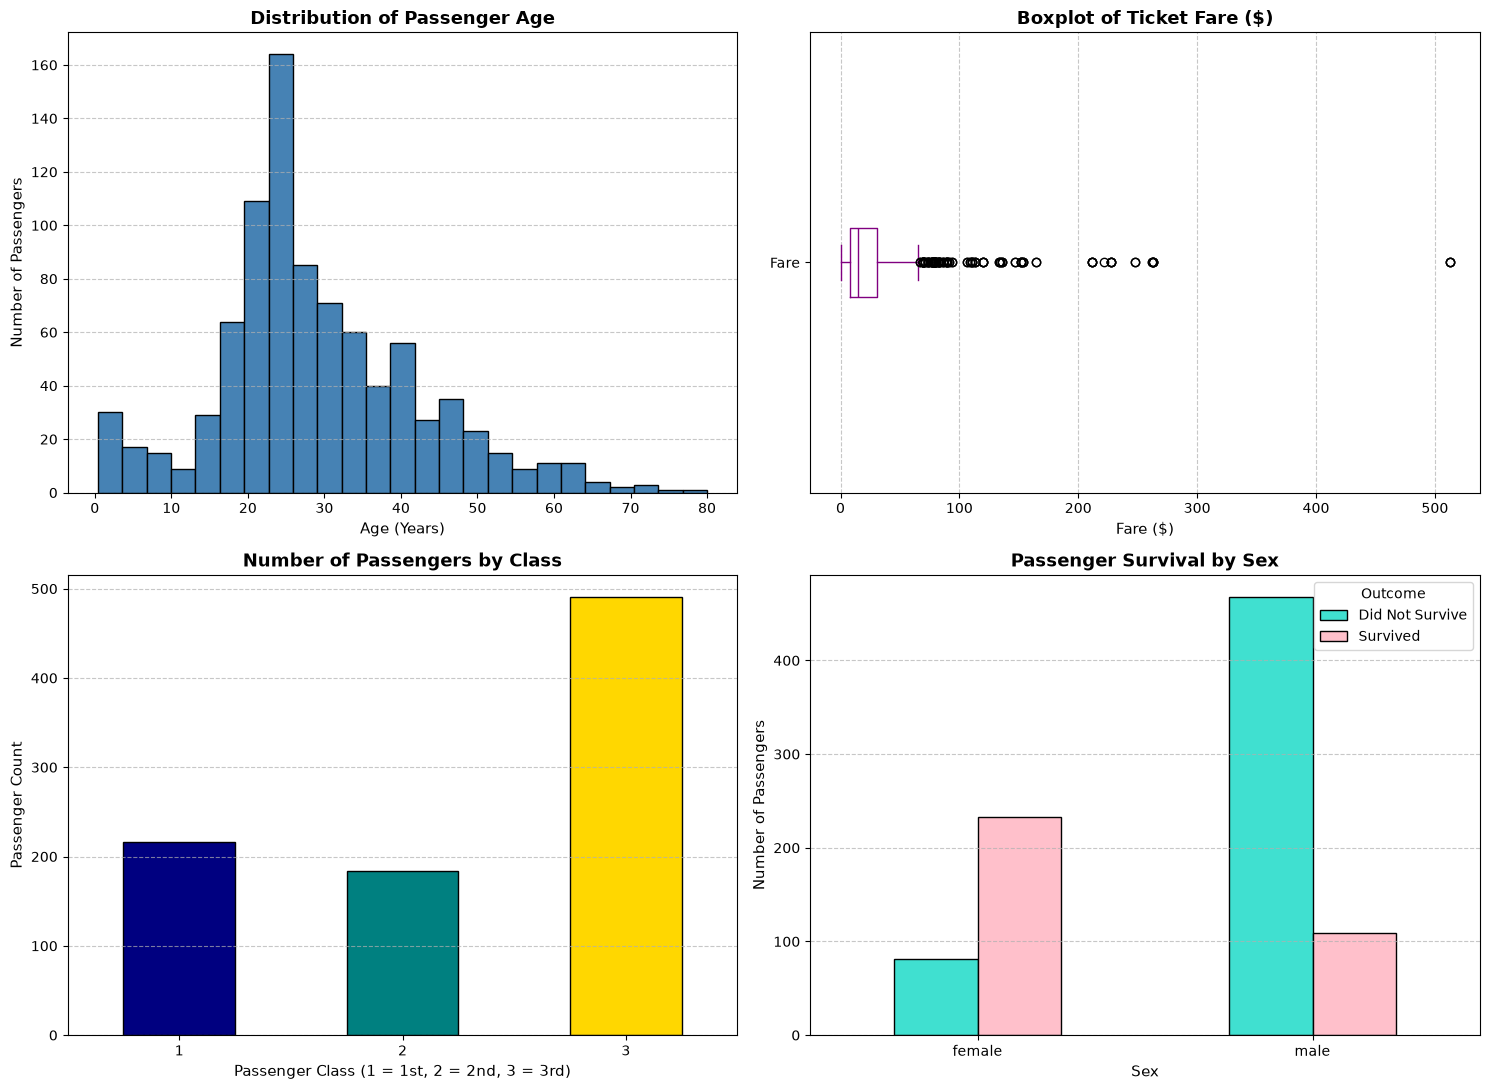

Histogram Analysis:
The histogram has the highest concentration around the passengers that are between
20-35 years old with another small bump for infant passengers. There is a little skew
 to the right since the passengers ages go up to 80. Additional investigation could
be done since earlier imputation influenced this specific data.

Boxplot Analysis:
The ticket prices are centered at the lower costs with plenty of outliers on the
expensive side. There is a decent right skew due to this. Possible investigation could
look into the $0 passengers to determine if they were crew or if it was a data entry error.

Bar Chart Analysis:
The 3rd class has the highest concentration of passengers, accounting for over half
of the people on board. I don't notice any unusual observations with this. I don't
feel that there is any additional investigation needed.

Grouped Bar Chart Analysis:
Female passengers survived at much higher rates than male passengers. I do not see
any unusual anomalies. Addit

In [41]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

#histogram for age
cleaned_data['Age'].plot(
    kind='hist', bins=25, color='steelblue', edgecolor='black', ax=axes[0, 0]
)
axes[0, 0].set_title('Distribution of Passenger Age', fontsize=13, fontweight='bold')
axes[0, 0].set_xlabel('Age (Years)', fontsize=11)
axes[0, 0].set_ylabel('Number of Passengers', fontsize=11)
axes[0, 0].grid(axis='y', linestyle='--', alpha=0.7)

#boxplot for fare and outliers
cleaned_data['Fare'].plot(
    kind='box', vert=False, color='purple', ax=axes[0, 1]
)
axes[0, 1].set_title('Boxplot of Ticket Fare ($)', fontsize=13, fontweight='bold')
axes[0, 1].set_xlabel('Fare ($)', fontsize=11)
axes[0, 1].grid(axis='x', linestyle='--', alpha=0.7)

#bar chart for # of passengers across class
class_counts = cleaned_data['Pclass'].value_counts().sort_index()
class_counts.plot(
    kind='bar', color=['navy', 'teal', 'gold'], edgecolor='black', rot=0, ax=axes[1, 0]
)
axes[1, 0].set_title('Number of Passengers by Class', fontsize=13, fontweight='bold')
axes[1, 0].set_xlabel('Passenger Class (1 = 1st, 2 = 2nd, 3 = 3rd)', fontsize=11)
axes[1, 0].set_ylabel('Passenger Count', fontsize=11)
axes[1, 0].grid(axis='y', linestyle='--', alpha=0.7)

#grouped bar cart
#I'm choosing to look at survival counts across sex
survival_by_sex = pd.crosstab(cleaned_data['Sex'], cleaned_data['Survived'])
survival_by_sex.columns = ['Did Not Survive', 'Survived']

survival_by_sex.plot(
    kind='bar',
    color=['turquoise', 'pink'],
    edgecolor='black',
    rot=0,
    ax=axes[1, 1]
)
axes[1, 1].set_title('Passenger Survival by Sex', fontsize=13, fontweight='bold')
axes[1, 1].set_xlabel('Sex', fontsize=11)
axes[1, 1].set_ylabel('Number of Passengers', fontsize=11)
axes[1, 1].legend(title='Outcome')
axes[1, 1].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()
print("Histogram Analysis:")
print("The histogram has the highest concentration around the passengers that are between\n20-35 years old with another small bump for infant passengers. There is a little skew\n to the right since the passengers ages go up to 80. Additional investigation could\nbe done since earlier imputation influenced this specific data.")
print("\nBoxplot Analysis:")
print("The ticket prices are centered at the lower costs with plenty of outliers on the\nexpensive side. There is a decent right skew due to this. Possible investigation could\nlook into the $0 passengers to determine if they were crew or if it was a data entry error.")
print("\nBar Chart Analysis:")
print("The 3rd class has the highest concentration of passengers, accounting for over half\nof the people on board. I don't notice any unusual observations with this. I don't\nfeel that there is any additional investigation needed.")
print("\nGrouped Bar Chart Analysis:")
print("Female passengers survived at much higher rates than male passengers. I do not see\nany unusual anomalies. Additional investigation could be done to compare this data\nwith class and that could be interesting. I did not form this chart that way because\nthe prompt said 'or' and not 'and'.")


In [40]:
#Final thoughts
print("Conclusion:")
print("The Titanic dataset indicates disparities in passenger composition and survival. Only\n38.4% of passengers survived with survival being heavily influenced by gender. Ticket\nprices were centered around the lower end, but this may be because the crew did not need\nto buy passage. There are significant outliers in the ticket fares, with the highest\nbeing $512.33. Limitations include 77.1% missing values in Cabin and 19.9% missing\nvalues in Age.")

Conclusion:
The Titanic dataset indicates disparities in passenger composition and survival. Only
38.4% of passengers survived with survival being heavily influenced by gender. Ticket
prices were centered around the lower end, but this may be because the crew did not need
to buy passage. There are significant outliers in the ticket fares, with the highest
being $512.33. Limitations include 77.1% missing values in Cabin and 19.9% missing
values in Age.
